Reproducing the approach in research paper: Grover search revisited; application to image pattern matching
https://drive.google.com/drive/folders/1P8hQX70d_kkbKl8Eg5Qv5fDm1YqB7Q4e

In [1]:
%pip install numpy matplotlib seaborn pylatexenc "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import random
import numpy as np
import pandas as pd
import sys
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_state_qsphere

STEP 1: Develop the AAE layers using PQC for dataset encoding

In [3]:
class ApproximateAmplitudeEncoder:
    def __init__(self, dataset, query, depth_A=6, depth_B=3,
                 epochs_A=500, epochs_B=300):

        self.dataset = np.asarray(dataset, dtype=float)
        self.query = np.asarray(query, dtype=float)

        self.N_I = len(dataset) # number of items in the dataset
        self.N_D = len(dataset[0])  # number of features in each item

        self.n_index_q = math.ceil(math.log2(self.N_I))
        self.n_data_q = math.ceil(math.log2(self.N_D))

        self.padded_N_I = 2 ** self.n_index_q
        self.padded_N_D = 2 ** self.n_data_q

        self.total_q = self.n_index_q + self.n_data_q

        self.depth_A = depth_A
        self.depth_B = depth_B
        self.epochs_A = epochs_A
        self.epochs_B = epochs_B

        self.original = np.zeros(
            (self.N_I, self.padded_N_D)
        )

        # 🔴 work on dataset and query normalization 

        # row-wise normalization of the dataset
        for k in range(self.N_I):
            row = self.dataset[k]
            row = row / np.linalg.norm(row)
            self.original[k, :self.N_D] = row

        self.database_target = np.zeros(
            self.padded_N_D * self.padded_N_I
        )

        for k in range(self.N_I):
            for j in range(self.N_D):
                self.database_target[
                    j * self.padded_N_I + k
                ] = self.original[k, j] / np.sqrt(self.N_I)

        self.query_target = np.zeros(self.padded_N_D)

        q = self.query / np.linalg.norm(self.query)
        self.query_target[:self.N_D] = q

        self.H_A = self.hadamard(self.total_q)
        self.H_B = self.hadamard(self.n_data_q)

        self.A_target_prob = self.database_target ** 2
        self.B_target_prob = self.query_target ** 2

        self.A_target_H_prob = (
            self.H_A @ self.database_target # matrix multiplication
        ) ** 2

        self.B_target_H_prob = (
            self.H_B @ self.query_target
        ) ** 2

        self.K_A = self.kernel(len(self.database_target))
        self.K_B = self.kernel(len(self.query_target))

        rng = np.random.default_rng(42) # random number generator for reproducibility

        self.parameters_A = rng.uniform(
            -np.pi, np.pi,
            self.depth_A * self.total_q
        )

        self.parameters_B = rng.uniform(
            -np.pi, np.pi,
            self.depth_B * self.n_data_q
        )

        self.train()

    def hadamard(self, n):

        H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

        for _ in range(n - 1):
            H = np.kron(H, H) / np.sqrt(2) # kronecker product to create n-qubit Hadamard

        return H

    def kernel(self, N):
        # create a Gaussian kernel matrix of size N x N
        # K(xi​,xj​) = e ^ [−γ.(xi​−xj​)^2]

        x = np.arange(N)    # create an array of indices from 0 to N-1

        return np.exp(
            -64 * (x[:, None] - x[None, :]) ** 2
        )

    def mmd(self, q, p, K):
        return (
            q @ K @ q
            + p @ K @ p
            - 2 * q @ K @ p
        )

    def create_A(self, parameters):
        qc = QuantumCircuit(self.total_q)
        t = 0

        for _ in range(self.depth_A):
            # rotation layer
            for q in range(self.total_q):
                qc.ry(parameters[t], q)
                t += 1

            # entangling layer
            for q in range(self.total_q - 1):
                qc.cx(q, q + 1)

        return qc

    def create_B(self, parameters):
        qc = QuantumCircuit(self.n_data_q)
        t = 0

        for _ in range(self.depth_B):

            for q in range(self.n_data_q):
                qc.ry(parameters[t], q)
                t += 1

            for q in range(self.n_data_q - 1):
                qc.cx(q, q + 1)

        return qc

    def state_A(self, parameters):

        return Statevector.from_instruction(
            self.create_A(parameters)
        ).data

    def state_B(self, parameters):

        return Statevector.from_instruction(
            self.create_B(parameters)
        ).data

    def loss_gradient(self, parameters, kind):

        if kind == "A":
            state = self.state_A(parameters)
            H = self.H_A
            K = self.K_A
            target = self.A_target_prob
            target_H = self.A_target_H_prob
            create = self.create_A
        else:
            state = self.state_B(parameters)
            H = self.H_B
            K = self.K_B
            target = self.B_target_prob
            target_H = self.B_target_H_prob
            create = self.create_B

        prob = np.abs(state) ** 2
        prob_H = np.abs(H @ state) ** 2

        L1 = self.mmd(prob, target, K)
        L2 = self.mmd(prob_H, target_H, K)

        loss = (L1 + L2) / 2

        dL1 = 2 * K @ (prob - target)
        dL2 = 2 * K @ (prob_H - target_H)

        gradient = np.zeros(len(parameters))

        for r in range(len(parameters)):

            p_plus = parameters.copy()
            p_minus = parameters.copy()

            p_plus[r] += np.pi / 2
            p_minus[r] -= np.pi / 2

            s_plus = Statevector.from_instruction(
                create(p_plus)
            ).data

            s_minus = Statevector.from_instruction(
                create(p_minus)
            ).data

            dp = (
                np.abs(s_plus) ** 2
                - np.abs(s_minus) ** 2
            ) / 2

            dp_H = (
                np.abs(H @ s_plus) ** 2
                - np.abs(H @ s_minus) ** 2
            ) / 2

            gradient[r] = (
                dL1 @ dp
                + dL2 @ dp_H
            ) / 2

        return loss, gradient

    def adam(self, parameters, kind, epochs):

        m = np.zeros_like(parameters)
        v = np.zeros_like(parameters)

        beta1 = 0.9
        beta2 = 0.999
        eps = 1e-8

        for epoch in range(1, epochs + 1):

            lr = 0.1 if epoch <= 100 else 0.01

            loss, grad = self.loss_gradient(
                parameters,
                kind
            )

            m = beta1 * m + (1 - beta1) * grad
            v = beta2 * v + (1 - beta2) * grad ** 2

            m_hat = m / (1 - beta1 ** epoch)
            v_hat = v / (1 - beta2 ** epoch)

            parameters -= (
                lr * m_hat /
                (np.sqrt(v_hat) + eps)
            )

            if epoch % 50 == 0:
                print(
                    f"{kind}: epoch {epoch}, "
                    f"loss = {loss:.6f}"
                )

        return parameters

    def train(self):

        print("\nTraining A(theta_a)")

        self.parameters_A = self.adam(
            self.parameters_A,
            "A",
            self.epochs_A
        )

        print("\nTraining B(theta_b)")

        self.parameters_B = self.adam(
            self.parameters_B,
            "B",
            self.epochs_B
        )

        self.plot_encoding()

    def plot_encoding(self):

        A_state = self.state_A(self.parameters_A)

        approx = np.zeros_like(self.original)

        for k in range(self.N_I):
            for j in range(self.N_D):
                approx[k, j] = (
                    A_state[
                        j * self.padded_N_I + k
                    ].real * np.sqrt(self.N_I)
                )

        B_state = self.state_B(self.parameters_B)

        query_approx = B_state.real[:self.N_D]

        fig, ax = plt.subplots(1, 2, figsize=(12, 4))

        ax[0].plot(
            self.original.flatten(),
            "o-",
            label="Original"
        )

        ax[0].plot(
            approx.flatten(),
            "s--",
            label="AAE"
        )

        ax[0].set_xlabel("Data element")
        ax[0].set_ylabel("Normalized amplitude")
        ax[0].set_title("Database: Original vs AAE")
        ax[0].legend()

        ax[1].plot(
            self.query_target[:self.N_D],
            "o-",
            label="Original query"
        )

        ax[1].plot(
            query_approx,
            "s--",
            label="AAE query"
        )

        ax[1].set_xlabel("Feature")
        ax[1].set_ylabel("Amplitude")
        ax[1].set_title("Query: Original vs AAE")
        ax[1].legend()

        plt.tight_layout()
        plt.show()

STEP 2: Run Grover Search algorithm with the AAE layers

In [4]:
class groverSearch:

    def initialize(self):

        qc = QuantumCircuit(self.total_qubits)

        qc.compose(
            self.AAE.create_A(self.aae_parameters_A),
            qubits=self.index_q + self.data_q,
            inplace=True
        )

        qc.x(self.ancilla)
        qc.h(self.ancilla)

        return qc

    def mark_target(self, qc):

        qc.x(self.data_q)

        qc.mcx(
            self.data_q,
            self.ancilla
        )

        qc.x(self.data_q)

        return qc

    def oracle(self):

        qc = QuantumCircuit(
            self.total_qubits
        )

        qc.compose(
            self.AAE.create_B(
                self.aae_parameters_B
            ).inverse(),
            qubits=self.data_q,
            inplace=True
        )

        self.mark_target(qc)

        qc.compose(
            self.AAE.create_B(
                self.aae_parameters_B
            ),
            qubits=self.data_q,
            inplace=True
        )

        return qc

    def diffuser(self):

        qc = QuantumCircuit(
            self.n_I + self.n_D
        )

        all_q = self.index_q + self.data_q

        B = self.AAE.create_B(
            self.aae_parameters_B
        )

        A = self.AAE.create_A(
            self.aae_parameters_A
        )

        qc.compose(
            B,
            qubits=self.data_q,
            inplace=True
        )

        qc.compose(
            A.inverse(),
            qubits=all_q,
            inplace=True
        )

        qc.x(all_q)

        if len(all_q) == 1:
            qc.z(all_q[0])
        else:
            qc.h(all_q[-1])
            qc.mcx(
                all_q[:-1],
                all_q[-1]
            )
            qc.h(all_q[-1])

        qc.x(all_q)

        qc.compose(
            A,
            qubits=all_q,
            inplace=True
        )

        qc.compose(
            B.inverse(),
            qubits=self.data_q,
            inplace=True
        )

        return qc

    def inversion_state(self):

        U = QuantumCircuit(
            self.n_I + self.n_D
        )

        U.compose(
            self.AAE.create_A(
                self.aae_parameters_A
            ),
            qubits=self.index_q + self.data_q,
            inplace=True
        )

        U.compose(
            self.AAE.create_B(
                self.aae_parameters_B
            ).inverse(),
            qubits=self.data_q,
            inplace=True
        )

        return Statevector.from_instruction(U)

    def index_probabilities(self, qc):

        state = Statevector.from_instruction(qc).data

        main_qubits = self.n_I + self.n_D
        probs = np.zeros(self.padded_N_I)

        for k in range(self.padded_N_I):

            probs[k] = (
                abs(state[k]) ** 2
                + abs(
                    state[k + 2 ** main_qubits]
                ) ** 2
            )

        return probs

    def visualize(self, qc, title):

        probs = self.index_probabilities(qc)

        plt.figure(figsize=(8, 4))

        plt.bar(
            range(self.padded_N_I),
            probs
        )

        plt.xlabel("Database index")
        plt.ylabel("Probability")
        plt.title(title)

        plt.show()

        return probs

    def run(self, dataset, query, no_of_shots=512):

        self.N_I = len(dataset)
        self.N_D = len(dataset[0])

        self.n_I = math.ceil(
            math.log2(self.N_I)
        )

        self.n_D = math.ceil(
            math.log2(self.N_D)
        )

        self.padded_N_I = 2 ** self.n_I
        self.padded_N_D = 2 ** self.n_D

        self.index_q = list(
            range(self.n_I)
        )

        self.data_q = list(
            range(
                self.n_I,
                self.n_I + self.n_D
            )
        )

        self.ancilla = (
            self.n_I + self.n_D
        )

        self.total_qubits = (
            self.n_I + self.n_D + 1
        )

        print("N_I =", self.N_I)
        print("N_D =", self.N_D)
        print("Index qubits =", self.n_I)
        print("Data qubits =", self.n_D)
        print("Total qubits =", self.total_qubits)

        self.AAE = ApproximateAmplitudeEncoder(
            dataset,
            query,
            depth_A=6,
            depth_B=3,
            epochs_A=500,
            epochs_B=300
        )

        self.aae_parameters_A = (
            self.AAE.parameters_A
        )

        self.aae_parameters_B = (
            self.AAE.parameters_B
        )

        psi = self.inversion_state().data

        p = np.sqrt(
            np.sum(
                np.abs(
                    psi[:self.padded_N_I]
                ) ** 2
            )
        )

        theta = np.arcsin(
            np.clip(p, 0, 1)
        )

        no_of_iter = max(
            1,
            int(
                np.floor(
                    np.arccos(p) /
                    (2 * theta)
                )
            )
        )

        print("\nInitial overlap =", p)
        print("Grover iterations =", no_of_iter)

        index_register = QuantumRegister(
            self.n_I,
            name="index"
        )

        data_register = QuantumRegister(
            self.n_D,
            name="data"
        )

        ancilla_register = QuantumRegister(
            1,
            name="ancilla"
        )

        classical_register = ClassicalRegister(
            self.n_I,
            name="index_result"
        )

        qc = QuantumCircuit(
            index_register,
            data_register,
            ancilla_register,
            classical_register
        )

        qc.compose(
            self.initialize(),
            inplace=True
        )

        self.visualize(
            qc,
            "Initial state"
        )

        for t in range(no_of_iter):

            qc.compose(
                self.oracle(),
                qubits=(
                    self.index_q
                    + self.data_q
                    + [self.ancilla]
                ),
                inplace=True
            )

            qc.compose(
                self.diffuser(),
                qubits=(
                    self.index_q
                    + self.data_q
                ),
                inplace=True
            )

            self.visualize(
                qc,
                f"After Grover iteration {t + 1}"
            )

        self.qc = qc

        state = Statevector.from_instruction(qc)
        probs = self.index_probabilities(qc)

        print("\nFinal index probabilities:")

        for k, probability in enumerate(probs):
            print(
                f"index {k}: "
                f"{probability:.6f}"
            )

        self.qc.measure(
            self.index_q,
            range(self.n_I)
        )

        simulator = AerSimulator()

        compiled = transpile(
            self.qc,
            simulator
        )

        result = simulator.run(
            compiled,
            shots=no_of_shots
        ).result()

        print("\nMeasurement results:")
        print(result.get_counts())

        return probs

    def draw_circuit(self):

        display(
            self.qc.draw("mpl")
        )

    def analysis(self):

        print("REGISTER ANALYSIS")
        print("Database elements:", self.N_I)
        print("Features:", self.N_D)
        print("Index qubits:", self.n_I)
        print("Data qubits:", self.n_D)
        print("Ancilla:", 1)

        print("\nCIRCUIT ANALYSIS")
        print("Total qubits:", self.qc.num_qubits)
        print("Width:", self.qc.width())
        print("Size:", self.qc.size())
        print("Depth:", self.qc.depth())

        print("\nOPERATION COUNT")
        print(self.qc.count_ops())

In [5]:
dataset = [
    [random.randint(0, 255) for _ in range(4)] for _ in range(5)
]
query = dataset[random.randint(0, len(dataset) - 1)]

In [6]:
dataset

[[22, 190, 38, 150],
 [133, 237, 59, 25],
 [35, 144, 219, 98],
 [105, 159, 62, 207],
 [107, 45, 215, 36]]

In [ ]:
query

[105, 159, 62, 207]

: 

In [ ]:
GS = groverSearch()

probs = GS.run(
    dataset,
    query,
    no_of_shots=512
)

N_I = 5
N_D = 4
Index qubits = 3
Data qubits = 2
Total qubits = 6


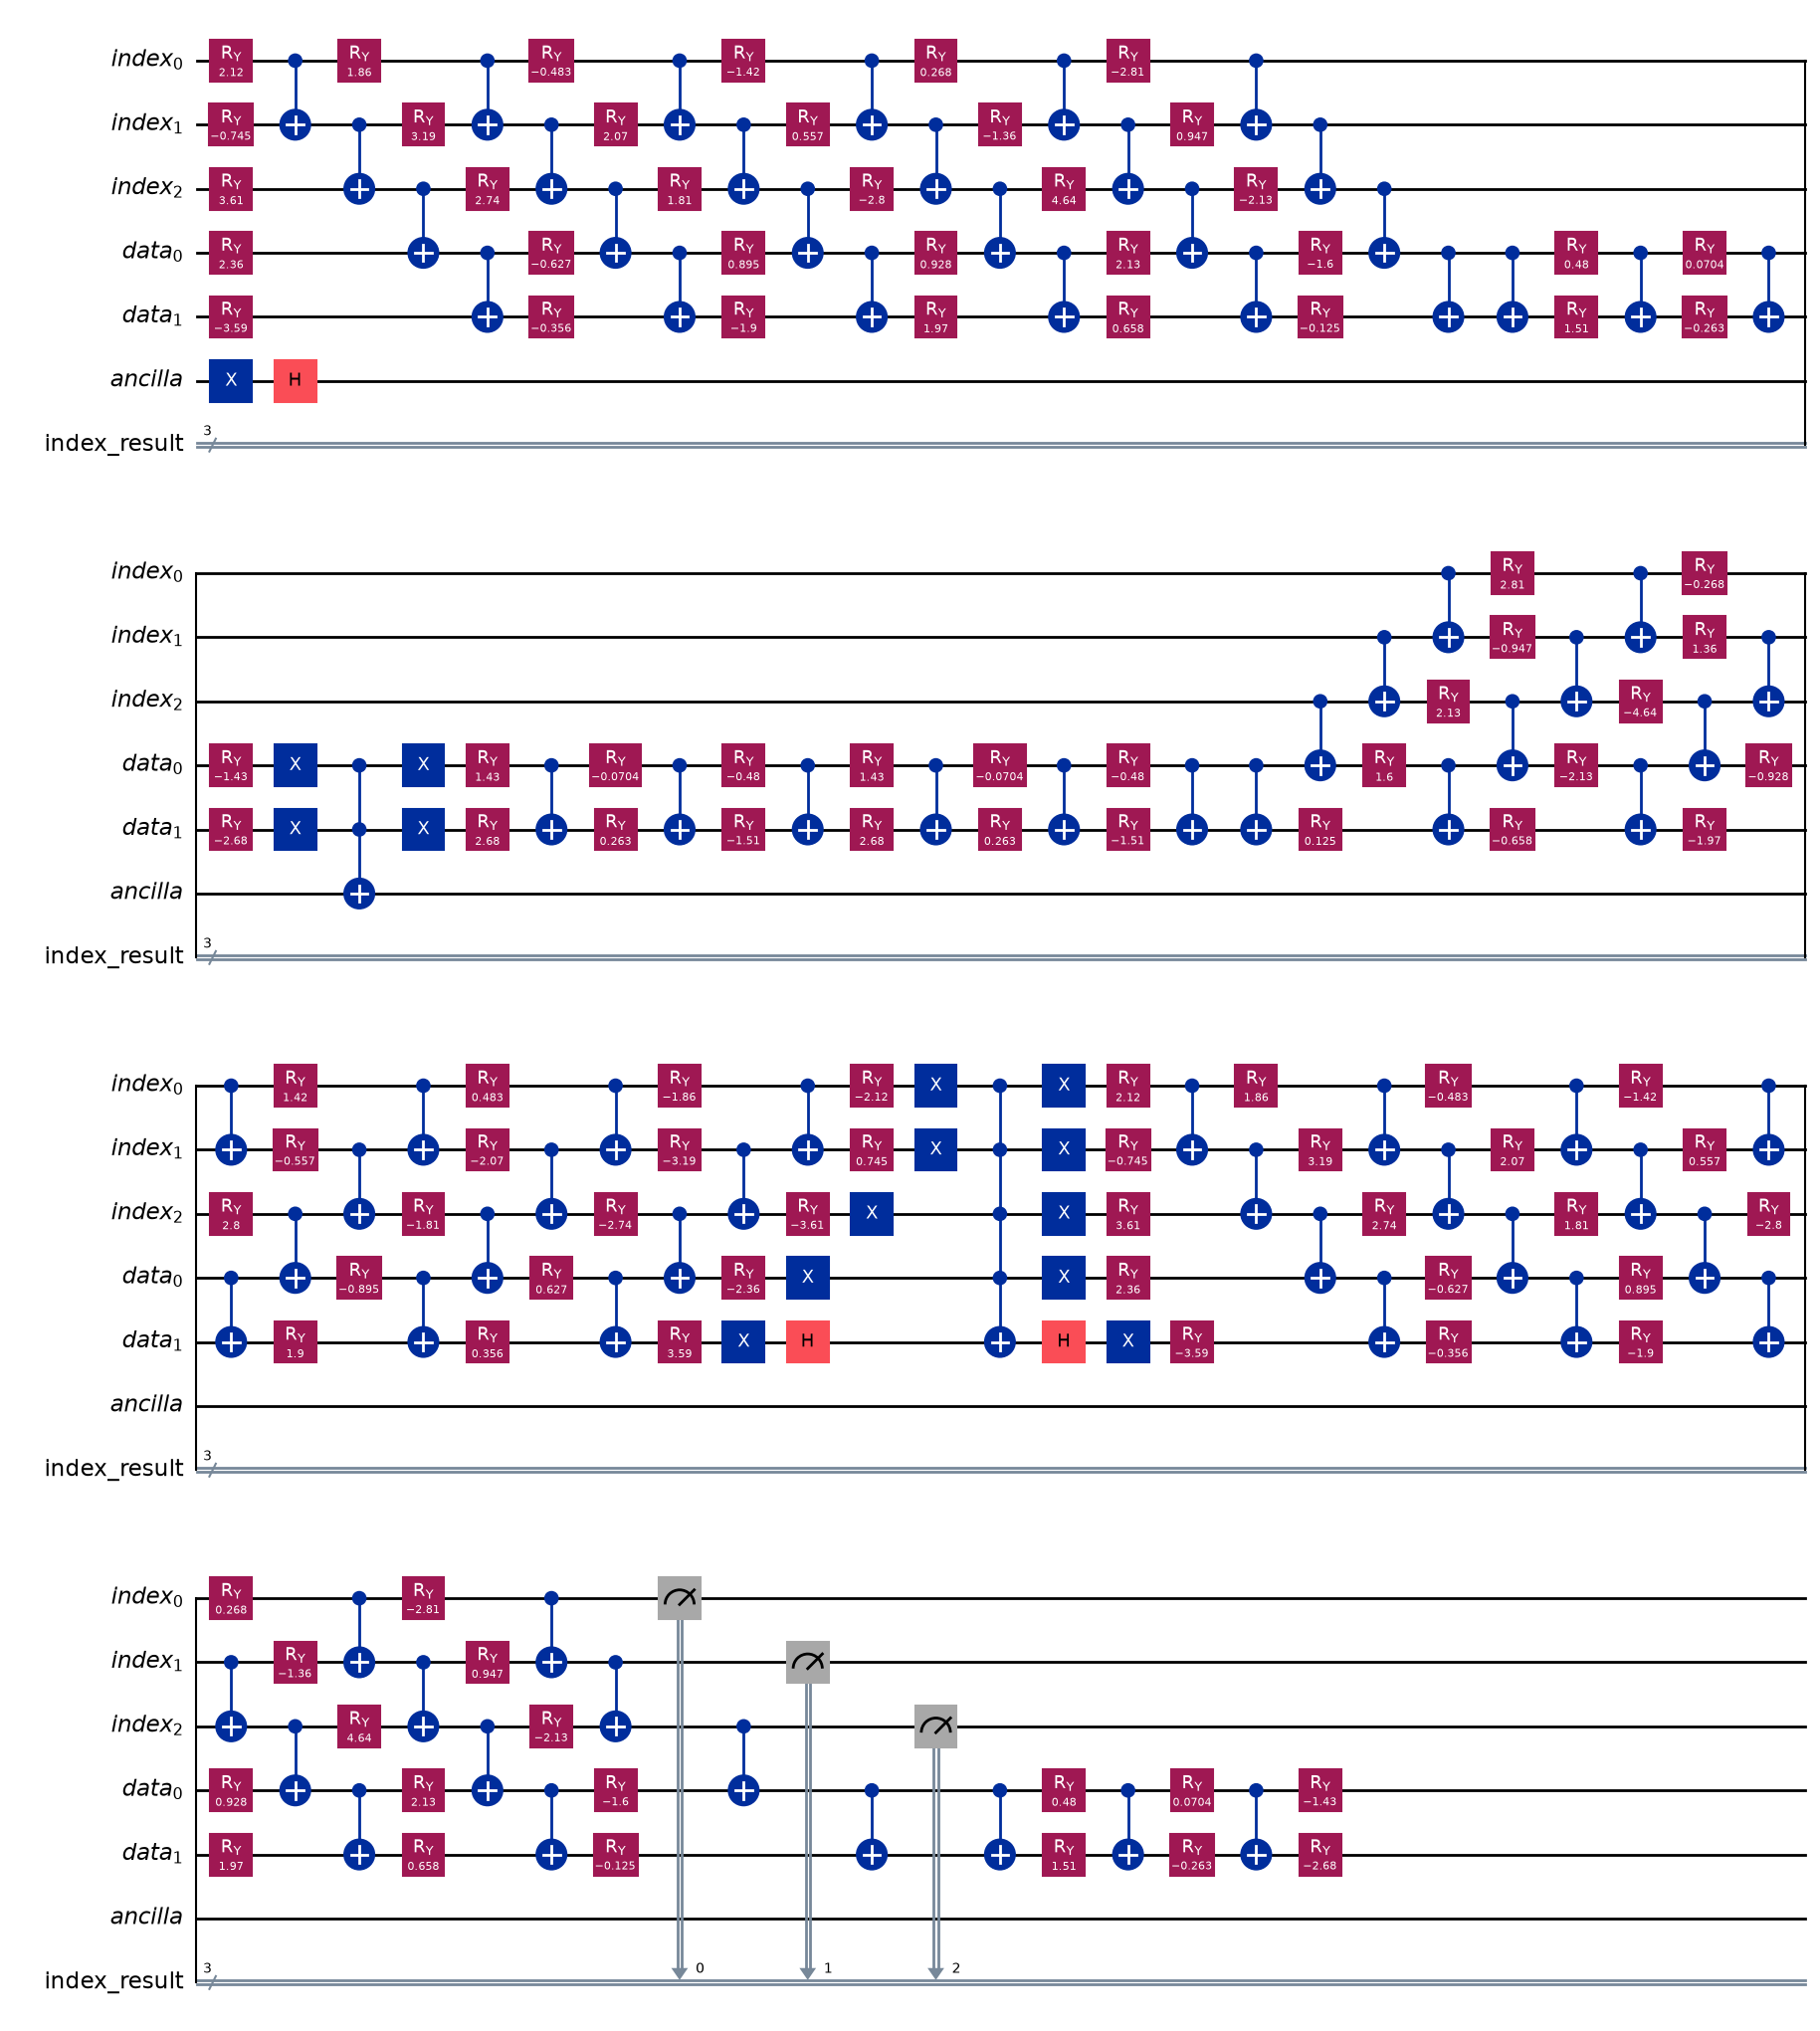

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()

REGISTER ANALYSIS
Database elements: 5
Features: 4
Index qubits: 3
Data qubits: 2
Ancilla: 1

CIRCUIT ANALYSIS
Total qubits: 6
Width: 9
Size: 221
Depth: 90

OPERATION COUNT
OrderedDict({'ry': 114, 'cx': 84, 'x': 15, 'h': 3, 'measure': 3, 'ccx': 1, 'mcx': 1})
